In [12]:
import os, sys, shutil, subprocess
from dotenv import find_dotenv, load_dotenv

# Load machine-specific settings (SUMO_HOME, SUMO_FOLDER) from a local .env file, if there is one
load_dotenv(find_dotenv(usecwd=True))

# 1) Use SUMO_HOME if it is already set on this computer
SUMO_HOME = os.environ.get("SUMO_HOME")

# 2) Otherwise, try a pip installation of SUMO (eclipse-sumo)
if not SUMO_HOME:
    try:
        import sumo
        SUMO_HOME = getattr(sumo, "SUMO_HOME", None)
    except ImportError:
        pass

# 3) Otherwise, work it out from where the "sumo" program is (.../bin/sumo)
if not SUMO_HOME and shutil.which("sumo"):
    SUMO_HOME = os.path.dirname(os.path.dirname(os.path.realpath(shutil.which("sumo"))))

if SUMO_HOME:
    os.environ["SUMO_HOME"] = SUMO_HOME
    sys.path.append(os.path.join(SUMO_HOME, "tools"))
import traci

def sumo_binary(name):
    """Full path to a SUMO program (sumo, sumo-gui, netconvert)."""
    if SUMO_HOME:
        for candidate in (name, name + ".exe"):
            path = os.path.join(SUMO_HOME, "bin", candidate)
            if os.path.exists(path):
                return path
    return shutil.which(name) or name

print("SUMO_HOME :", SUMO_HOME)
print("sumo      :", sumo_binary("sumo"))

SUMO_HOME : /opt/anaconda3/envs/platooning/lib/python3.12/site-packages/sumo
sumo      : /opt/anaconda3/envs/platooning/lib/python3.12/site-packages/sumo/bin/sumo


In [ ]:
FOLDER = os.environ.get("SUMO_FOLDER", ".")    # folder with the SUMO files (set in .env)

SCENARIO = "osm"            # "example" = 600 m test road, "osm" = road exported from OpenStreetMap
if SCENARIO == "example":
    CONFIG_FILE = os.path.join(FOLDER, "accident.sumocfg")
    EDGE = "highway"
    CRASH_POSITION = 300.0  # metres from the start of the highway (road is 600 m)
else:
    FOLDER = os.path.join(FOLDER, "scenarios", "2026-10-29-23-52-03")
    CONFIG_FILE = os.path.join(FOLDER, "osm.sumocfg")
    EDGE = "1229067689#1"   # direction A: one straight 1797 m edge
    CRASH_POSITION = 900.0 # metres from the start of the edge
LANES = [EDGE + "_0", EDGE + "_1"]   # 0 = kerb lane (right in the example, left in the OSM road)

USE_GUI = True              # False = run without the window (faster)
GUI_DELAY_MS = 100          # pause between steps in the GUI (bigger = slower)

CRASH_VEHICLE = "crash_car" # front car: stops suddenly
HIT_VEHICLE = "hit_car"     # car behind: does not brake and hits it
HIT_SPEED = 12.0            # m/s, speed at which hit_car drives into crash_car
ACCIDENT_DURATION = 300.0   # seconds the two cars block the lane
SIM_END = 600.0             # seconds (same as <end> in the .sumocfg)
REPORT_EVERY = 20.0         # seconds between measurements

# Check that the files are there
print(f"{CONFIG_FILE:40s}", "OK" if os.path.exists(CONFIG_FILE) else "MISSING")

/Users/hubertkrzemieniewski/Documents/university/year4/final-year-project/sumo_accident/scenarios/2026-10-29-23-52-03/osm.sumocfg OK


In [14]:
REBUILD_NETWORK = False

if REBUILD_NETWORK:
    result = subprocess.run(
        [sumo_binary("netconvert"),
         "--node-files", os.path.join(FOLDER, "highway.nod.xml"),
         "--edge-files", os.path.join(FOLDER, "highway.edg.xml"),
         "--output-file", os.path.join(FOLDER, "highway.net.xml")],
        capture_output=True, text=True)
    print(result.stdout, result.stderr)

In [15]:
import pandas as pd

def run_simulation():
    binary = sumo_binary("sumo-gui" if USE_GUI else "sumo")
    cmd = [binary, "-c", CONFIG_FILE, "--start", "--collision.action", "warn"]
    if USE_GUI:
        cmd += ["--delay", str(GUI_DELAY_MS)]
    try:
        traci.close()   # close a connection left open by an earlier run
    except Exception:
        pass
    traci.start(cmd)

    crash_time = None
    hit_armed = False   # hit_car has been told not to brake
    hit_done = False    # the collision has happened
    cleared = False
    arrived_in_window = 0
    on_edge = set()     # vehicles seen on EDGE, so only arrivals from EDGE count as throughput
    next_report = REPORT_EVERY
    rows = []

    try:
        while traci.simulation.getMinExpectedNumber() > 0 and traci.simulation.getTime() < SIM_END:
            traci.simulationStep()
            t = traci.simulation.getTime()
            ids = traci.vehicle.getIDList()
            arrived = [v for v in traci.simulation.getArrivedIDList() if v in on_edge]
            arrived_in_window += len(arrived)
            on_edge.difference_update(arrived)
            on_edge.update(traci.edge.getLastStepVehicleIDs(EDGE))

            # keep both crash cars in the right lane until the accident is cleared
            if not cleared:
                for v in (CRASH_VEHICLE, HIT_VEHICLE):
                    if v in ids:
                        traci.vehicle.setLaneChangeMode(v, 0)

            # --- 1. Front car stops suddenly ---
            if crash_time is None and CRASH_VEHICLE in ids:
                if traci.vehicle.getLanePosition(CRASH_VEHICLE) >= CRASH_POSITION:
                    traci.vehicle.setDecel(CRASH_VEHICLE, 9.0)
                    traci.vehicle.setSpeed(CRASH_VEHICLE, 0.0)
                    traci.vehicle.setColor(CRASH_VEHICLE, (255, 0, 0, 255))
                    crash_time = t
                    print(f"t={t:7.1f}s  {CRASH_VEHICLE} STOPPED at x={CRASH_POSITION:.0f} m")

            # --- 2. Car behind: switch off its safety braking ---
            if crash_time is not None and not hit_armed and HIT_VEHICLE in ids:
                traci.vehicle.setSpeedMode(HIT_VEHICLE, 0)
                traci.vehicle.setSpeed(HIT_VEHICLE, HIT_SPEED)
                traci.vehicle.setColor(HIT_VEHICLE, (255, 140, 0, 255))
                hit_armed = True
                print(f"t={t:7.1f}s  {HIT_VEHICLE} is not braking")

            # --- 3. Collision: hit_car reaches crash_car and stops on contact ---
            if hit_armed and not hit_done and HIT_VEHICLE in ids and CRASH_VEHICLE in ids:
                rear_of_front_car = (traci.vehicle.getLanePosition(CRASH_VEHICLE)
                                     - traci.vehicle.getLength(CRASH_VEHICLE))
                gap = rear_of_front_car - traci.vehicle.getLanePosition(HIT_VEHICLE)
                step_distance = traci.vehicle.getSpeed(HIT_VEHICLE) * traci.simulation.getDeltaT()
                if gap <= step_distance + 0.3:
                    traci.vehicle.setSpeed(HIT_VEHICLE, 0.0)
                    traci.vehicle.setColor(HIT_VEHICLE, (255, 0, 0, 255))
                    hit_done = True
                    print(f"t={t:7.1f}s  COLLISION: {HIT_VEHICLE} hit {CRASH_VEHICLE}")

            # --- 4. Clear the accident ---
            if crash_time is not None and not cleared and t >= crash_time + ACCIDENT_DURATION:
                for v in (CRASH_VEHICLE, HIT_VEHICLE):
                    if v in ids:
                        traci.vehicle.setSpeed(v, -1)
                        traci.vehicle.setSpeedMode(v, 31)
                        traci.vehicle.setLaneChangeMode(v, 1621)
                cleared = True
                print(f"t={t:7.1f}s  accident CLEARED")

            # --- 5. Measure ---
            if t >= next_report:
                phase = "before" if crash_time is None else ("accident" if not cleared else "after")
                rows.append({
                    "time": t,
                    "phase": phase,
                    "throughput_veh_per_min": arrived_in_window * 60.0 / REPORT_EVERY,
                    "vehicles_on_road": traci.edge.getLastStepVehicleNumber(EDGE),
                    "stopped_vehicles": traci.edge.getLastStepHaltingNumber(EDGE),
                    "speed_right_lane": traci.lane.getLastStepMeanSpeed(LANES[0]),
                    "speed_left_lane": traci.lane.getLastStepMeanSpeed(LANES[1]),
                })
                arrived_in_window = 0
                next_report += REPORT_EVERY
    finally:
        traci.close()

    return pd.DataFrame(rows), crash_time

In [ ]:
df, crash_time = run_simulation()
df.to_csv(os.path.join(FOLDER, "results.csv"), index=False)
df.head(10)

 Retrying in 1 seconds
t=   61.4s  crash_car STOPPED at x=900 m
t=   61.4s  hit_car is not braking
t=   66.8s  COLLISION: hit_car hit crash_car
t=  361.4s  accident CLEARED


In [ ]:
df.groupby("phase", sort=False)[["throughput_veh_per_min", "stopped_vehicles",
                                 "speed_right_lane", "speed_left_lane"]].mean().round(1)

,throughput_veh_per_min,stopped_vehicles,speed_right_lane,speed_left_lane
phase,,,,
before,9.0,0.0,32.2,31.0
accident,17.0,5.9,8.1,27.2
after,44.6,0.6,18.1,21.0


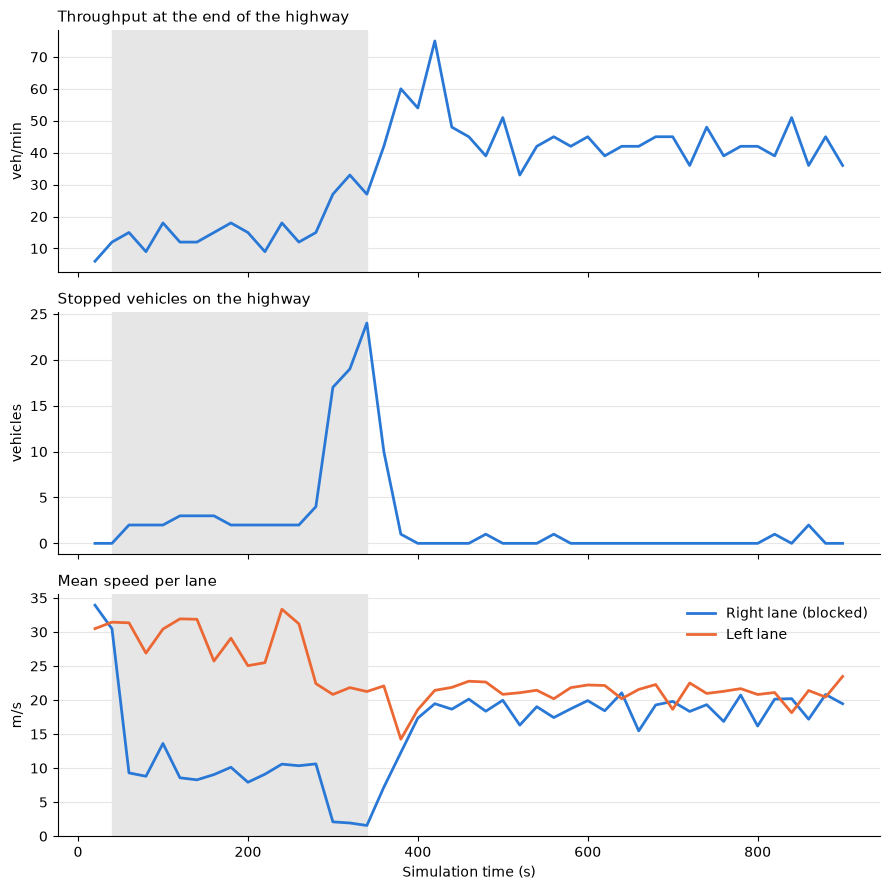

In [ ]:
import matplotlib.pyplot as plt

BLUE, ORANGE = "#2a78d6", "#eb6834"
fig, axes = plt.subplots(3, 1, figsize=(9, 9), sharex=True)

def style(ax, title, ylabel):
    if crash_time is not None:
        ax.axvspan(crash_time, crash_time + ACCIDENT_DURATION, color="0.9", zorder=0)
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", color="0.9", linewidth=0.8)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

axes[0].plot(df["time"], df["throughput_veh_per_min"], color=BLUE, linewidth=2)
style(axes[0], "Throughput at the end of the highway", "veh/min")

axes[1].plot(df["time"], df["stopped_vehicles"], color=BLUE, linewidth=2)
style(axes[1], "Stopped vehicles on the highway", "vehicles")

axes[2].plot(df["time"], df["speed_right_lane"], color=BLUE, linewidth=2, label="Lane 0 (blocked)")
axes[2].plot(df["time"], df["speed_left_lane"], color=ORANGE, linewidth=2, label="Lane 1")
style(axes[2], "Mean speed per lane", "m/s")
axes[2].legend(frameon=False)
axes[2].set_xlabel("Simulation time (s)")

plt.tight_layout()
plt.show()